
# 🎥 2D → 3D (SBS) Converter for **Oculus Quest 3** — Colab Notebook

**Что делает ноутбук:** берёт обычное видео, предсказывает глубину **нейросетью** (MiDaS по умолчанию, опционально ZoeDepth),
синтезирует правый ракурс через **depth‑based view synthesis** (z‑buffer warp), при необходимости затирает дырки (inpainting),
и упаковывает результат в **SBS (Side‑by‑Side)** формат (half/full), совместимый с Quest 3 (через Skybox/DEOVR/Meta Gallery и т.п.).

**Основные стадии:**
1. Извлечь кадры и аудио из исходного видео (FFmpeg).
2. Оценить глубину на каждом кадре нейросетью (MiDaS по умолчанию; опционально ZoeDepth).
3. (Опционально) Устойчивость по времени: RAFT‑оптический поток (torchvision) + EMA сглаживание по направленной деформации.
4. Синтез правого глаза по карте глубины (z‑buffer forward warp).
5. Заливка раскрытых областей (inpainting): по умолчанию OpenCV Telea; опционально LaMa (нейросеть).
6. Сборка SBS (half/full) и финальный рендер (FFmpeg), перенос оригинального аудио.

> ⚠️ **Примечание про производительность:** Видеоконверсия ресурсоёмкая. Для длинных/4K видео уменьшайте `target_height` или увеличивайте `frame_stride`.


In [1]:
#@title ⬇️ Установка зависимостей (FFmpeg, PyTorch, MiDaS, и утилиты)
%%bash
set -e
apt-get update -qq
apt-get install -y -qq ffmpeg

python -m pip install --upgrade pip
pip install -q opencv-python imageio[ffmpeg] tqdm einops timm numpy matplotlib
# Torch/torchvision обычно уже стоят в Colab, но обновим до совместимой связки
pip install -q --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu121

# MiDaS через torch.hub; тем не менее ставим requirements (только timm/torch уже есть)
# pip install -q git+https://github.com/isl-org/MiDaS.git

# ZoeDepth (опционально). Если установка/импорт не получится — падать не будем, используем MiDaS.
# pip install -q zoedepth || true

# LaMa (опционально). Мы не активируем по умолчанию, только hook, поскольку веса тяжелые.
# pip install -q git+https://github.com/Sanster/lama-cleaner.git || true


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 33.4 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [2]:
#@title 📦 Импорты и выбор устройства
import os, sys, math, subprocess, json, glob, shutil
from pathlib import Path

import cv2
import numpy as np
import imageio.v3 as iio
from tqdm import tqdm
import torch
import torch.nn.functional as F

# RAFT опционален; если недоступен, аккуратно отработаем без него
try:
    from torchvision.models.optical_flow import raft_large, Raft_Large_Weights
    HAVE_RAFT = True
except Exception as e:
    print("Torchvision RAFT недоступен, продолжим без него:", e)
    HAVE_RAFT = False

# Torch device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)
torch.set_grad_enabled(False)


DEVICE: cuda


torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [3]:
#@title ⚙️ Конфиг (заполните и запустите)
#@markdown Путь может быть локальным (загрузка в Colab) или из Google Drive (смонтируйте вручную в следующей ячейке).
input_video_path = "/content/input.mp4" #@param {type:"string"}
output_dir = "/content/outputs" #@param {type:"string"}

#@markdown **Формат для Quest 3**
sbs_mode = "full" #@param ["half", "full"]
#@markdown - `half` → стандартный SBS (левый/правый сжат по ширине в 2 раза), например 1920x1080 кадр из 2×(960x1080)
#@markdown - `full` → полный SBS по ширине (в 2 раза шире исходника) для более высокого качества

#@markdown **Геометрия 3D**
max_shift_px = 32 #@param {type:"slider", "min":8, "max":96, "step":2}
#@markdown Максимальный горизонтальный сдвиг (в пикселях) для ближайших объектов. Больше → сильнее параллакс.

#@markdown **Размер и шаг по кадрам (для ускорения)**
target_height = 0 #@param {type:"integer"}
#@markdown 0 = не менять размер; иначе видео будет ресайзнуто по высоте до этого значения (ширина с сохранением пропорций).
frame_stride = 1 #@param {type:"integer"}
#@markdown Обработка каждого `frame_stride`‑го кадра (1 = все кадры). Для экономии времени можно выбрать 2–4, тогда недостающие кадры интерполируются при рендере.

#@markdown **Нейро‑модули**
use_zoedepth_if_available = True #@param {type:"boolean"}
use_raft_temporal_smoothing = True #@param {type:"boolean"}
alpha_ema = 0.7 #@param {type:"number"}
#@markdown Вес свежего кадра в EMA (0.5–0.8 типично).

use_lama_inpainting = True #@param {type:"boolean"}
#@markdown LaMa даёт более "умную" заливку, но требует доп.весов и времени. По умолчанию выключено.

#@markdown **Аудио**
keep_audio = True #@param {type:"boolean"}
audio_codec = "aac" #@param ["aac", "copy"]
#@markdown Если исходный аудио‑кодек не совместим с MP4, используйте `aac`.

os.makedirs(output_dir, exist_ok=True)
print("OK: конфиг принят.")


OK: конфиг принят.


In [ ]:
#@title 💽 (Опционально) Подключить Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# После монтирования можно указывать пути вида "/content/drive/MyDrive/..." в конфиге выше.
pass


In [4]:
#@title 🔧 Утилиты (FFmpeg, IO, ресайз)
def run_cmd(cmd):
    print("CMD:", " ".join(cmd))
    p = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if p.returncode != 0:
        print(p.stdout)
        raise RuntimeError(f"Command failed with exit {p.returncode}")
    return p.stdout

def probe_fps(video_path):
    cmd = [
        "ffprobe", "-v", "error", "-select_streams", "v:0",
        "-show_entries", "stream=avg_frame_rate,r_frame_rate",
        "-of", "default=noprint_wrappers=1:nokey=1", video_path
    ]
    out = run_cmd(cmd).strip().splitlines()
    for line in out:
        if "/" in line:
            num, den = line.split("/")
            try:
                num, den = float(num), float(den)
                if den != 0:
                    return num/den
            except:
                pass
    return 24.0

def extract_frames_and_audio(video_path, frames_dir, audio_path, stride=1, target_h=0):
    os.makedirs(frames_dir, exist_ok=True)
    fps = probe_fps(video_path)
    vf_parts = []
    if target_h and target_h > 0:
        vf_parts.append(f"scale=-2:{int(target_h)}")
    if stride > 1:
        vf_parts.append(f"fps=fps={fps/stride}")
    vf = ",".join(vf_parts) if vf_parts else "null"
    vf = vf if vf != "null" else "fps=fps="+str(fps/stride if stride>1 else fps)

    cmd_frames = [
        "ffmpeg", "-y", "-i", video_path,
        "-vf", vf, os.path.join(frames_dir, "%06d.png")
    ]
    run_cmd(cmd_frames)

    if keep_audio:
        if audio_codec == "copy":
            cmd_audio = ["ffmpeg", "-y", "-i", video_path, "-vn", "-acodec", "copy", audio_path]
        else:
            cmd_audio = ["ffmpeg", "-y", "-i", video_path, "-vn", "-acodec", "aac", "-b:a", "192k", audio_path]
        try:
            run_cmd(cmd_audio)
        except Exception as e:
            print("⚠️ Не удалось извлечь аудио, продолжим без него:", e)
            return fps, False
        return fps/stride if stride>1 else fps, True
    else:
        return fps/stride if stride>1 else fps, False

def list_frames(frames_dir):
    return sorted(glob.glob(os.path.join(frames_dir, "*.png")))

print("Утилиты готовы.")


Утилиты готовы.


In [5]:
#@title 🤖 Загрузка модели глубины (MiDaS по умолчанию; ZoeDepth при наличии)
def get_midas_model():
    midas = torch.hub.load("intel-isl/MiDaS", "DPT_Large").to(DEVICE).eval()
    transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
    transform = transforms.dpt_transform
    return midas, transform

def get_zoedepth_model():
    try:
        from zoedepth.utils.config import get_config
        from zoedepth.models.builder import build_model
        from zoedepth.utils.checkpoint import load_network
    except Exception as e:
        print("ZoeDepth не установлен/не импортируется:", e)
        return None, None

    conf = get_config("zoedepth", "infer")
    conf["model"]["name"] = "zoedepth_nk"
    model = build_model(conf).to(DEVICE).eval()
    model = load_network(model, conf)
    print("ZoeDepth загружен.")
    return model, None

class DepthEstimator:
    def __init__(self, try_zoe=False):
        self.kind = "midas"
        self.model, self.transform = None, None
        if try_zoe:
            model, _ = get_zoedepth_model()
            if model is not None:
                self.kind = "zoe"
                self.model = model
        if self.model is None:
            self.model, self.transform = get_midas_model()
            self.kind = "midas"
        print("Depth model:", self.kind)

    def predict_disp01(self, bgr):
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        if self.kind == "midas":
            # 1) Вперед по MiDaS
            inp = self.transform(rgb).to(DEVICE)              # [1,3,h,w]
            pred = self.model(inp)                            # обычно [1,H',W'] (без канала), но держим универсально
            # 2) Приводим к форме [N,1,H',W']
            if pred.ndim == 3:                                # [1,H',W']
                pred = pred.unsqueeze(1)                      # [1,1,H',W']
            elif pred.ndim == 2:                              # [H',W'] — маловероятно, но на всякий случай
                pred = pred.unsqueeze(0).unsqueeze(0)         # [1,1,H',W']
            # 3) Ресайз к исходному кадру (H,W)
            H, W = rgb.shape[:2]
            pred = F.interpolate(pred, size=(H, W), mode="bicubic", align_corners=False)  # [1,1,H,W]
            pred = pred[0,0]                                  # -> [H,W]
            # 4) Нормализация в [0,1] (инверсная глубина)
            x = pred.float()
            x = (x - x.min()) / (x.max() - x.min() + 1e-8)
            return x.detach().cpu().numpy()

        else:
            # ZoeDepth -> depth, конвертируем в нормированный "диспаритет"
            t = torch.from_numpy(rgb).permute(2,0,1).float().unsqueeze(0).to(DEVICE) / 255.0
            pred = self.model.infer(t)                        # depth, обычно [1,1,H,W] или [1,H,W]
            if pred.ndim == 3:                                # [1,H,W] -> [1,1,H,W]
                pred = pred.unsqueeze(1)
            d = pred[0,0].detach().cpu().numpy()              # [H,W]
            inv = 1.0 / (d + 1e-6)
            p5, p95 = np.percentile(inv, [5, 95])
            inv = np.clip((inv - p5) / (p95 - p5 + 1e-8), 0, 1)
            return inv


depth_estimator = DepthEstimator(try_zoe=use_zoedepth_if_available)


ZoeDepth не установлен/не импортируется: No module named 'zoedepth'


/usr/local/lib/python3.12/dist-packages/torch/hub.py:330: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(


Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Downloading: "https://github.com/isl-org/MiDaS/releases/download/v3/dpt_large_384.pt" to /root/.cache/torch/hub/checkpoints/dpt_large_384.pt


100%|██████████| 1.28G/1.28G [00:12<00:00, 107MB/s] 


Depth model: midas


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


In [6]:
#@title 🌊 (Опционально) RAFT-сглаживание по времени
RAFT = True
RAFT_WEIGHTS = None
if use_raft_temporal_smoothing and HAVE_RAFT:
    try:
        RAFT_WEIGHTS = Raft_Large_Weights.C_T_V2
        RAFT = raft_large(weights=RAFT_WEIGHTS, progress=True).to(DEVICE).eval()
        print("RAFT загружен.")
    except Exception as e:
        print("Не удалось загрузить RAFT:", e)
        RAFT = None
else:
    print("RAFT сглаживание выключено или недоступно.")


def raft_flow(prev_bgr, curr_bgr):
    """
    Возвращает flow [H,W,2] (dx, dy) для деформации prev->curr.
    Совместим с разными сигнатурами вывода RAFT (списки/тензоры/и т.д.).
    """
    # --> RGB float32 [0,1]
    pr = cv2.cvtColor(prev_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    cr = cv2.cvtColor(curr_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

    # Нормализация: по умолчанию к [-1,1], что в целом совместимо с RAFT-weights;
    # (альтернатива — RAFT_WEIGHTS.transforms(), см. вариант 2)
    t1 = torch.from_numpy(pr).permute(2,0,1).unsqueeze(0).to(DEVICE)  # [1,3,H,W]
    t2 = torch.from_numpy(cr).permute(2,0,1).unsqueeze(0).to(DEVICE)
    t1 = (t1 - 0.5) / 0.5
    t2 = (t2 - 0.5) / 0.5

    with torch.no_grad():
        out = RAFT(t1, t2)

    # Универсальный разбор выхода
    flow_up = None
    if isinstance(out, (list, tuple)):
        # torchvision иногда возвращает список пирамид; берём последний (самый «апсемпленный»)
        flow_up = out[-1]
    elif isinstance(out, dict):
        # на всякий случай — если словарь
        # берём первый тензор
        for v in out.values():
            flow_up = v
            break
    else:
        # тензор напрямую
        flow_up = out

    # Ожидаем тензор [N,2,H,W] или [N,H,W,2]
    if flow_up.ndim == 4 and flow_up.shape[1] == 2:
        flow = flow_up[0].permute(1,2,0).detach().cpu().numpy()  # -> [H,W,2]
    elif flow_up.ndim == 4 and flow_up.shape[-1] == 2:
        flow = flow_up[0].detach().cpu().numpy()                 # [H,W,2]
    else:
        raise RuntimeError(f"Неизвестная форма выхода RAFT: {tuple(flow_up.shape)}")

    return flow  # (dx, dy)


def warp_with_flow(tensor_2d, flow):
    H, W = tensor_2d.shape
    grid_y, grid_x = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
    xs = (grid_x - flow[...,0])
    ys = (grid_y - flow[...,1])
    xs_norm = (xs / (W-1)) * 2 - 1
    ys_norm = (ys / (H-1)) * 2 - 1
    grid = np.stack([xs_norm, ys_norm], axis=-1)
    grid_t = torch.from_numpy(grid).float().unsqueeze(0).to(DEVICE)
    src = torch.from_numpy(tensor_2d).float().unsqueeze(0).unsqueeze(0).to(DEVICE)
    warped = F.grid_sample(src, grid_t, mode='bilinear', padding_mode='border', align_corners=True)
    return warped.squeeze().detach().cpu().numpy()


Downloading: "https://download.pytorch.org/models/raft_large_C_T_V2-1bb1363a.pth" to /root/.cache/torch/hub/checkpoints/raft_large_C_T_V2-1bb1363a.pth


100%|██████████| 20.1M/20.1M [00:00<00:00, 29.2MB/s]

RAFT загружен.


In [7]:
#@title 🧩 Синтез правого глаза (z-buffer warp) + Inpaint + Сборка SBS
def synthesize_right(bgr_left, disp01, max_shift):
    H, W, _ = bgr_left.shape
    shift = (disp01 * max_shift).astype(np.float32)
    order = np.argsort(disp01.ravel())  # даль -> ближ

    xs, ys = np.meshgrid(np.arange(W), np.arange(H))
    xs_f = xs.ravel().astype(np.float32)
    ys_f = ys.ravel().astype(np.int32)
    shift_f = shift.ravel()

    x2 = np.floor(xs_f - shift_f).astype(np.int32)
    x2 = np.clip(x2, 0, W-1)

    right = np.zeros_like(bgr_left)
    filled = np.zeros((H,W), dtype=np.bool_)

    src_idx = order
    tgt_x = x2[order]
    tgt_y = ys_f[order]

    right_flat = right.reshape(-1, 3)
    left_flat  = bgr_left.reshape(-1, 3)
    filled_flat = filled.reshape(-1)

    tgt_flat_idx = (tgt_y * W + tgt_x)
    CH = 2000000
    for i in range(0, len(src_idx), CH):
        sl = slice(i, i+CH)
        right_flat[tgt_flat_idx[sl]] = left_flat[src_idx[sl]]
        filled_flat[tgt_flat_idx[sl]] = True

    right = right_flat.reshape(H,W,3)
    filled = filled_flat.reshape(H,W)
    hole = ~filled
    return right, hole

def inpaint_frame(bgr, hole_mask):
    if not hole_mask.any():
        return bgr
    if use_lama_inpainting:
        # Подключите сюда LaMa при необходимости (требуются веса и отдельный вызов модели).
        pass
    hole_u8 = (hole_mask.astype(np.uint8))*255
    hole_u8 = cv2.dilate(hole_u8, np.ones((3,3), np.uint8), iterations=1)
    out = cv2.inpaint(bgr, hole_u8, 3, cv2.INPAINT_TELEA)
    return out

def pack_sbs(left_bgr, right_bgr, mode="half"):
    H, W, _ = left_bgr.shape
    if mode == "half":
        left_r  = cv2.resize(left_bgr,  (W//2, H), interpolation=cv2.INTER_AREA)
        right_r = cv2.resize(right_bgr, (W//2, H), interpolation=cv2.INTER_AREA)
        sbs = np.hstack([left_r, right_r])
    else:
        sbs = np.hstack([left_bgr, right_bgr])
    return sbs


In [8]:
#@title ▶️ Запуск конвейера
video_path = input_video_path
assert os.path.isfile(video_path), f"Исходное видео не найдено: {video_path}"

work_dir = Path(output_dir)
frames_dir = str(work_dir / "frames_src")
sbs_dir    = str(work_dir / "frames_sbs")
audio_path = str(work_dir / "audio.m4a")
out_video  = str(work_dir / ("output_SBS_" + ("half" if sbs_mode=="half" else "full") + ".mp4"))

for d in [frames_dir, sbs_dir]:
    os.makedirs(d, exist_ok=True)

fps, has_audio = extract_frames_and_audio(video_path, frames_dir, audio_path, stride=frame_stride, target_h=target_height)
print(f"FPS для сборки: {fps:.3f}  | Аудио: {'да' if has_audio else 'нет'}")

fpaths = list_frames(frames_dir)
assert len(fpaths) > 0, "Кадры не извлечены."
print("Кадров:", len(fpaths))

prev_bgr = None
prev_disp = None

for fp in tqdm(fpaths, desc="Processing frames"):
    bgr = cv2.imread(fp, cv2.IMREAD_COLOR)
    disp = depth_estimator.predict_disp01(bgr)

    if RAFT is not None and prev_bgr is not None and prev_disp is not None:
        flow = raft_flow(prev_bgr, bgr)  # prev->curr
        prev_disp_warped = warp_with_flow(prev_disp, flow)
        disp = alpha_ema*disp + (1.0 - alpha_ema)*prev_disp_warped
        disp = np.clip(disp, 0, 1)

    right, hole = synthesize_right(bgr, disp, max_shift_px)
    right = inpaint_frame(right, hole)

    sbs = pack_sbs(bgr, right, sbs_mode)
    out_name = os.path.basename(fp)
    cv2.imwrite(os.path.join(sbs_dir, out_name), sbs)

    prev_bgr = bgr
    prev_disp = disp

print("SBS кадры готовы:", len(list_frames(sbs_dir)))


CMD: ffprobe -v error -select_streams v:0 -show_entries stream=avg_frame_rate,r_frame_rate -of default=noprint_wrappers=1:nokey=1 /content/input.mp4
CMD: ffmpeg -y -i /content/input.mp4 -vf fps=fps=30.99173553719008 /content/outputs/frames_src/%06d.png
CMD: ffmpeg -y -i /content/input.mp4 -vn -acodec aac -b:a 192k /content/outputs/audio.m4a
FPS для сборки: 30.992  | Аудио: да
Кадров: 2588


Processing frames: 100%|██████████| 2588/2588 [55:12<00:00,  1.28s/it]

SBS кадры готовы: 2588


In [9]:
#@title 🎬 Финальный рендер (FFmpeg) — MP4 (H.264, yuv420p)
vpat = os.path.join(sbs_dir, "%06d.png")
if has_audio and keep_audio:
    cmd = [
        "ffmpeg", "-y", "-r", f"{fps:.6f}", "-i", vpat, "-i", audio_path,
        "-map", "0:v:0", "-map", "1:a:0",
        "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "18",
        "-c:a", audio_codec,
        "-shortest",
        out_video
    ]
else:
    cmd = [
        "ffmpeg", "-y", "-r", f"{fps:.6f}", "-i", vpat,
        "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "18",
        out_video
    ]
run_cmd(cmd)
print("Готово:", out_video)


CMD: ffmpeg -y -r 30.991736 -i /content/outputs/frames_sbs/%06d.png -i /content/outputs/audio.m4a -map 0:v:0 -map 1:a:0 -c:v libx264 -pix_fmt yuv420p -crf 18 -c:a aac -shortest /content/outputs/output_SBS_full.mp4
Готово: /content/outputs/output_SBS_full.mp4


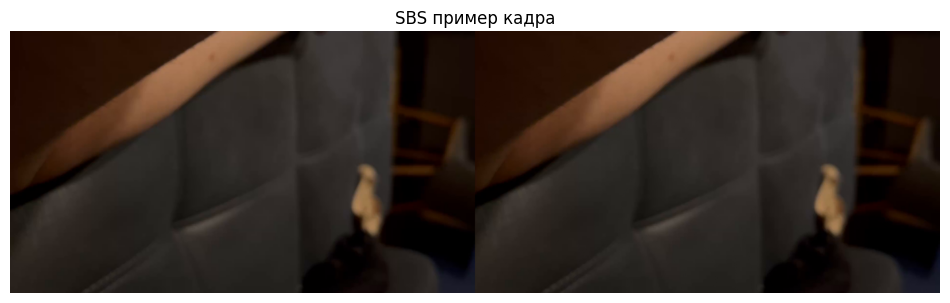

In [10]:
#@title 👀 Превью одного кадра
import matplotlib.pyplot as plt
samples = list_frames(sbs_dir)[:1]
if samples:
    img = cv2.imread(samples[0], cv2.IMREAD_COLOR)[:,:,::-1]
    plt.figure(figsize=(12,5))
    plt.imshow(img); plt.axis('off')
    plt.title("SBS пример кадра")
else:
    print("Нет кадров для превью.")
